# FXS / 06 — Re-running discovery: do the structures still show up, and are there new ones?

Iván (2026-11-11): run the FXS discovery scan again on the pairs of our structures — **EURUSD** (EURUSD-01, -02), **USDJPY** (USDJPY-01, -02) and **EURJPY** (EURJPY-02, in the 2026 portfolio test; EURJPY-01 failed) — over three windows:

| Window | Question |
|---|---|
| 2016–2020 | the original discovery (should reproduce FXS 01) |
| **2021–2025** | do the original structures still pass discovery on later data? are there **new** structures? |
| 2016–2025 | everything pooled |

Same method as FXS 01/002: both clocks (New York 17:00→17:00, UTC), every interval starting every 5 minutes and 15–240 minutes long (2,704 tests per pair and window), D1 Benjamini–Hochberg within the pair (q ≤ 0.05), D2 same sign in ≥ 80% of the years (4 of 5, 8 of 10), D3 |mean| > median spread + 0.70 bp commission, de-duplication, ≤ 10 candidates, rotated-day placebos (D0).

**Caution.** 2021–2025 has already been used to judge these structures, and 2026 has been seen, so a **new** structure found here has no untouched data left to confirm it: only trades from now on can. This notebook is descriptive.

In [1]:
import json, os, sys, tempfile, math
import datetime as dt
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PAIRS = ["EURUSD", "USDJPY", "EURJPY"]
WINDOWS = {"2016-2020": (dt.date(2016, 1, 1), dt.date(2020, 12, 31), "discovery"),
           "2021-2025": (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           "2016-2025": (dt.date(2016, 1, 1), dt.date(2025, 12, 31), "confirmation")}
N_PLACEBO = 20

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs06_")
    os.environ.pop("DUKASCOPY_DIR", None)
    N_PLACEBO = 3
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg0 = F.FXSConfig(n_placebo=N_PLACEBO)
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("06_synthetic" if SYNTHETIC else "06"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(PAIRS):
        F.write_synthetic_candles(base, p, dt.date(2015, 12, 28), dt.date(2025, 12, 31), seed=31 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)
    orig = pd.DataFrame([{"id": "EURUSD-02", "pair": "EURUSD", "clock": "NY", "start": 660, "end": 900, "direction": -1}])
else:
    orig = F.load_frozen_candidates(BRANCH).query("pair in @PAIRS").reset_index(drop=True)
orig["rule"] = [f"{'buy' if d > 0 else 'sell'} {F.slot_label(c, s)} -> {F.slot_label(c, e).split()[1]}" for c, s, e, d in
                zip(orig["clock"], orig["start"], orig["end"], orig["direction"])]
display(orig[["id", "pair", "rule"]])

,id,pair,rule
0,EURUSD-01,EURUSD,buy UTC 01:15 -> 03:15
1,EURUSD-02,EURUSD,sell NY 04:00 -> 08:00
2,USDJPY-01,USDJPY,sell UTC 00:55 -> 01:55
3,USDJPY-02,USDJPY,buy UTC 00:25 -> 00:55
4,EURJPY-01,EURJPY,sell NY 10:45 -> 11:00
5,EURJPY-02,EURJPY,buy NY 12:35 -> 16:35


## 1. Scan every pair in every window

The first run builds minute caches for the new windows (a few minutes per pair); the placebos take the longest.

In [3]:
scans, cands, d0 = {}, {}, []
for w, (a, b, stage) in WINDOWS.items():
    n_years = b.year - a.year + 1
    cfg = replace(cfg0, min_years_same_sign=math.ceil(0.8 * n_years))
    for p in PAIRS:
        panels = F.load_panels([p], a, b, stage, cfg)
        sc = pd.concat([F.scan_panel(panels[(p, c)], cfg) for c in F.CLOCKS], ignore_index=True)
        sc, cd = F.select_candidates(sc, cfg)
        if len(cd):
            cd["id"] = [f"new[{w}] {i}" for i in cd["id"]]      # not to be confused with the original structure ids
        sc["D123"] = sc["D1"] & sc["D2"] & sc["D3"]
        pl = F.placebo_counts(panels, cfg)
        real = int(sc["D123"].sum()); p95 = float(np.percentile(pl["D1_D2_D3"], 95))
        scans[(w, p)], cands[(w, p)] = sc, cd
        d0.append({"window": w, "pair": p, "years needed (D2)": cfg.min_years_same_sign, "D1": int(sc["D1"].sum()),
                   "D1+D2": int((sc["D1"] & sc["D2"]).sum()), "D1+D2+D3": real, "placebo p95": p95,
                   "D0": "STRUCTURE_FOUND" if real > p95 else "NO_STRUCTURE", "candidates": len(cd)})
        print(f"{w} {p}: D1 {int(sc['D1'].sum())}, D1-D3 {real}, placebo p95 {p95:.1f}, candidates {len(cd)}")
d0 = pd.DataFrame(d0)
display(d0.pivot(index="pair", columns="window", values=["D1+D2+D3", "D0", "candidates"]))
d0.to_csv(OUT / "06_summary_by_window.csv", index=False)

2016-2020 EURUSD: D1 205, D1-D3 45, placebo p95 0.0, candidates 2
2016-2020 USDJPY: D1 67, D1-D3 45, placebo p95 0.0, candidates 2
2016-2020 EURJPY: D1 79, D1-D3 31, placebo p95 0.9, candidates 2
2021-2025 EURUSD: D1 120, D1-D3 17, placebo p95 0.3, candidates 1
2021-2025 USDJPY: D1 108, D1-D3 19, placebo p95 1.9, candidates 3
2021-2025 EURJPY: D1 146, D1-D3 13, placebo p95 1.4, candidates 2
2016-2025 EURUSD: D1 312, D1-D3 34, placebo p95 0.4, candidates 1
2016-2025 USDJPY: D1 147, D1-D3 16, placebo p95 0.0, candidates 3
2016-2025 EURJPY: D1 279, D1-D3 29, placebo p95 0.0, candidates 1


D1+D2+D3                                   D0                                   candidates                    
window 2016-2020 2016-2025 2021-2025        2016-2020        2016-2025        2021-2025  2016-2020 2016-2025 2021-2025
pair                                                                                                                  
EURJPY        31        29        13  STRUCTURE_FOUND  STRUCTURE_FOUND  STRUCTURE_FOUND          2         1         2
EURUSD        45        34        17  STRUCTURE_FOUND  STRUCTURE_FOUND  STRUCTURE_FOUND          2         1         1
USDJPY        45        16        19  STRUCTURE_FOUND  STRUCTURE_FOUND  STRUCTURE_FOUND          2         3         3

## 2. The original structures in each window

The exact frozen interval looked up in each window's scan: mean (bps at the mid, in its trade direction), t, BH q, years with the same sign, filters passed, and whether it (or an overlapping interval) was selected as a candidate. `rank` = position by |t| among the pair's 2,704 tests.

In [4]:
rows = []
for _, r in orig.iterrows():
    seg = F._utc_segments(r["clock"], int(r["start"]), int(r["end"]))
    for w in WINDOWS:
        sc = scans[(w, r["pair"])]
        sc = sc.assign(rank=sc["t"].abs().rank(ascending=False, method="min").astype(int))
        hit = sc[(sc["clock"] == r["clock"]) & (sc["start"] == r["start"]) & (sc["end"] == r["end"])]
        if hit.empty:
            continue
        h = hit.iloc[0]
        cd = cands[(w, r["pair"])]
        over = [c["id"] for _, c in cd.iterrows() if F._overlap(seg, F._utc_segments(c["clock"], int(c["start"]), int(c["end"])))]
        rows.append({"structure": r["id"], "rule": r["rule"], "window": w, "mean bps (trade dir.)": h["mean_bps"] * r["direction"],
                     "t (trade dir.)": h["t"] * r["direction"], "q": h["q"], "years same sign": h["years_same_sign"],
                     "D1": h["D1"], "D2": h["D2"], "D3": h["D3"], "rank": int(h["rank"]),
                     "selected": bool(((cd["clock"] == r["clock"]) & (cd["start"] == r["start"]) & (cd["end"] == r["end"])).any()) if len(cd) else False,
                     "overlapping candidate": ", ".join(over) or "-"})
status = pd.DataFrame(rows)
display(status.round(3)); status.to_csv(OUT / "06_original_structures.csv", index=False)

,structure,rule,window,mean bps (trade dir.),t (trade dir.),q,years same sign,D1,D2,D3,rank,selected,overlapping candidate
0,EURUSD-01,buy UTC 01:15 -> 03:15,2016-2020,1.301,4.579,0.000,5,True,True,True,34,True,new[2016-2020] EURUSD-01
1,EURUSD-01,buy UTC 01:15 -> 03:15,2021-2025,0.508,2.132,0.297,5,False,True,False,300,False,-
2,EURUSD-01,buy UTC 01:15 -> 03:15,2016-2025,0.904,4.852,0.000,10,True,True,False,72,False,-
3,EURUSD-02,sell NY 04:00 -> 08:00,2016-2020,2.486,4.085,0.002,5,True,True,True,62,True,new[2016-2020] EURUSD-02
4,EURUSD-02,sell NY 04:00 -> 08:00,2021-2025,1.978,3.823,0.005,5,True,True,True,69,False,new[2021-2025] EURUSD-01
5,EURUSD-02,sell NY 04:00 -> 08:00,2016-2025,2.232,5.587,0.000,10,True,True,True,37,False,new[2016-2025] EURUSD-01
6,USDJPY-01,sell UTC 00:55 -> 01:55,2016-2020,1.868,4.905,0.003,5,True,True,True,1,True,new[2016-2020] USDJPY-01
7,USDJPY-01,sell UTC 00:55 -> 01:55,2021-2025,1.373,3.608,0.013,5,True,True,True,62,False,new[2021-2025] USDJPY-02
8,USDJPY-01,sell UTC 00:55 -> 01:55,2016-2025,1.620,6.016,0.000,10,True,True,True,8,False,new[2016-2025] USDJPY-01
9,USDJPY-02,buy UTC 00:25 -> 00:55,2016-2020,1.067,4.067,0.015,5,True,True,True,8,True,new[2016-2020] USDJPY-02


## 3. Candidates found in each window

`new?` = the candidate does not overlap any original structure of the same pair (in UTC time, New York intervals under both daylight-saving offsets).

In [5]:
allc = []
for (w, p), cd in cands.items():
    if cd.empty:
        continue
    o = orig[orig["pair"] == p]
    for _, c in cd.iterrows():
        seg = F._utc_segments(c["clock"], int(c["start"]), int(c["end"]))
        match = [x["id"] for _, x in o.iterrows() if F._overlap(seg, F._utc_segments(x["clock"], int(x["start"]), int(x["end"])))]
        allc.append({"window": w, "pair": p, "candidate": c["id"], "trade": f"{'buy' if c['direction'] > 0 else 'sell'} {c['start_time']} -> {c['end_time'].split()[1]}",
                     "minutes": c["minutes"], "mean bps": abs(c["mean_bps"]), "t": abs(c["t"]), "q": c["q"], "years same sign": c["years_same_sign"],
                     "cost bps": c["cost_bps"], "pooled Bonferroni |t|>=4.84": abs(c["t"]) >= 4.84,
                     "overlaps original": ", ".join(match) or "-", "new?": not match})
allc = pd.DataFrame(allc)
for w in WINDOWS:
    print(f"\n=== {w} ===")
    display(allc[allc["window"] == w].drop(columns="window").round(3))
allc.to_csv(OUT / "06_candidates.csv", index=False)


=== 2016-2020 ===


,pair,candidate,trade,minutes,mean bps,t,q,years same sign,cost bps,pooled Bonferroni |t|>=4.84,overlaps original,new?
0,EURUSD,new[2016-2020] EURUSD-01,buy UTC 01:15 -> 03:15,120,1.301,4.579,0.000,5,1.006,False,EURUSD-01,False
1,EURUSD,new[2016-2020] EURUSD-02,sell NY 04:00 -> 08:00,240,2.486,4.085,0.002,5,0.960,False,EURUSD-02,False
2,USDJPY,new[2016-2020] USDJPY-01,sell UTC 00:55 -> 01:55,60,1.868,4.905,0.003,5,0.977,True,USDJPY-01,False
3,USDJPY,new[2016-2020] USDJPY-02,buy UTC 00:25 -> 00:55,30,1.067,4.067,0.015,5,0.979,False,USDJPY-02,False
4,EURJPY,new[2016-2020] EURJPY-01,sell NY 10:45 -> 11:00,15,1.194,4.147,0.027,4,1.097,False,EURJPY-01,False
5,EURJPY,new[2016-2020] EURJPY-02,buy NY 12:35 -> 16:35,240,1.837,4.128,0.027,5,1.256,False,EURJPY-02,False



=== 2021-2025 ===


,pair,candidate,trade,minutes,mean bps,t,q,years same sign,cost bps,pooled Bonferroni |t|>=4.84,overlaps original,new?
6,EURUSD,new[2021-2025] EURUSD-01,sell NY 07:45 -> 08:00,15,1.046,6.240,0.00,5,0.971,True,EURUSD-02,False
7,USDJPY,new[2021-2025] USDJPY-01,buy NY 15:20 -> 16:20,60,1.268,7.070,0.00,5,1.103,True,-,True
8,USDJPY,new[2021-2025] USDJPY-02,sell UTC 00:55 -> 01:10,15,1.181,5.927,0.00,5,1.120,True,USDJPY-01,False
9,USDJPY,new[2021-2025] USDJPY-03,buy UTC 00:25 -> 00:55,30,1.315,4.580,0.00,5,1.119,False,USDJPY-02,False
10,EURJPY,new[2021-2025] EURJPY-01,buy NY 14:55 -> 16:55,120,1.660,6.375,0.00,5,1.553,True,EURJPY-02,False
11,EURJPY,new[2021-2025] EURJPY-02,sell NY 06:00 -> 08:00,120,1.391,3.218,0.03,4,1.305,False,-,True



=== 2016-2025 ===


,pair,candidate,trade,minutes,mean bps,t,q,years same sign,cost bps,pooled Bonferroni |t|>=4.84,overlaps original,new?
12,EURUSD,new[2016-2025] EURUSD-01,sell NY 07:45 -> 08:00,15,0.989,7.168,0.000,9,0.961,True,EURUSD-02,False
13,USDJPY,new[2016-2025] USDJPY-01,sell UTC 00:55 -> 01:25,30,1.308,6.942,0.000,10,1.050,True,USDJPY-01,False
14,USDJPY,new[2016-2025] USDJPY-02,buy UTC 00:25 -> 00:55,30,1.191,6.120,0.000,10,1.052,True,USDJPY-02,False
15,USDJPY,new[2016-2025] USDJPY-03,buy NY 12:55 -> 16:55,240,1.421,4.397,0.001,10,1.136,False,-,True
16,EURJPY,new[2016-2025] EURJPY-01,buy NY 12:55 -> 16:55,240,1.963,6.225,0.000,9,1.425,True,EURJPY-02,False


## 4. The stacked day: 2016–2020 vs 2021–2025

Mean cumulative mid return from the day start (bps) with ± 2 SE bands, per pair and clock. Shaded: the original structures' windows (green = long, red = short).

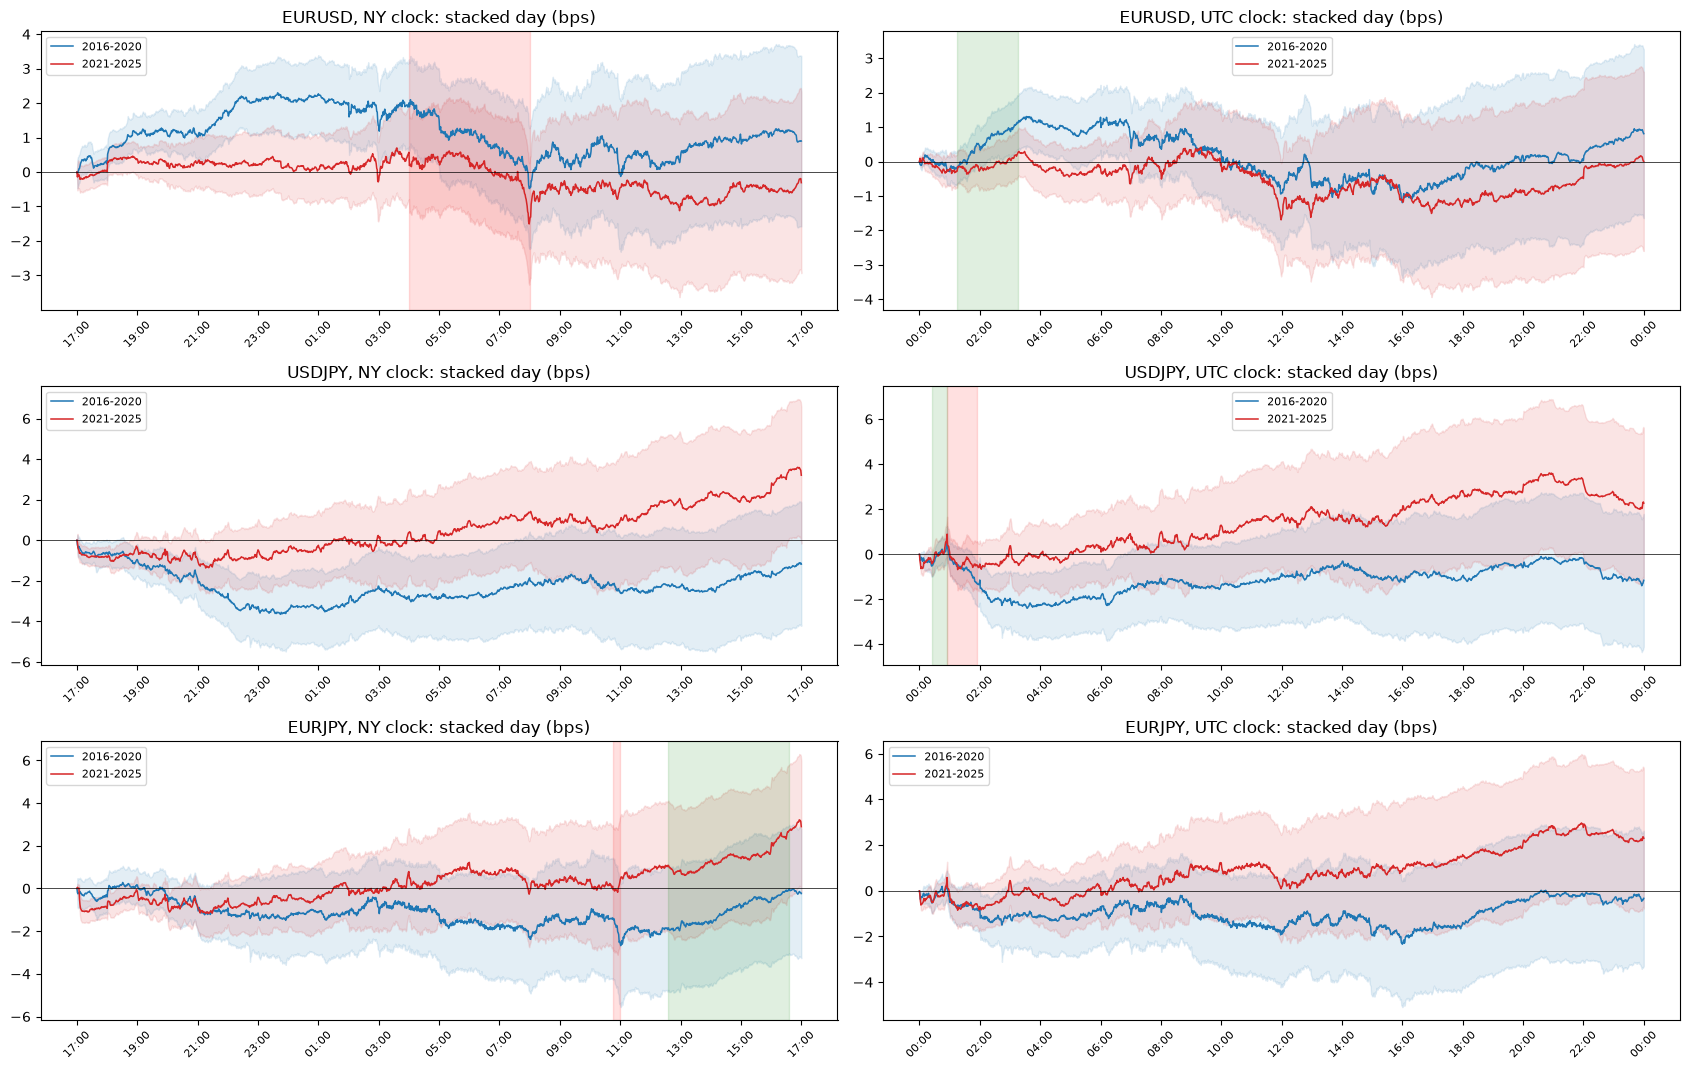

In [6]:
fig, axes = plt.subplots(len(PAIRS), 2, figsize=(17, 3.6 * len(PAIRS)), squeeze=False)
for i, p in enumerate(PAIRS):
    for j, clock in enumerate(F.CLOCKS):
        ax = axes[i, j]
        for w, col in (("2016-2020", "C0"), ("2021-2025", "C3")):
            a, b, stage = WINDOWS[w]
            pr = F.profile(F.load_panels([p], a, b, stage, cfg0, clocks=(clock,))[(p, clock)])
            x = pr.index / 60
            ax.plot(x, pr["cum_mean_bps"], color=col, lw=1.1, label=w)
            ax.fill_between(x, pr["cum_mean_bps"] - 2 * pr["cum_se_bps"], pr["cum_mean_bps"] + 2 * pr["cum_se_bps"], color=col, alpha=0.12)
        for _, r in orig[(orig["pair"] == p) & (orig["clock"] == clock)].iterrows():
            ax.axvspan(r["start"] / 60, r["end"] / 60, color="green" if r["direction"] > 0 else "red", alpha=0.12)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_xticks(range(0, 25, 2)); ax.set_xticklabels([F.slot_label(clock, 60 * h).split()[1] for h in range(0, 25, 2)], rotation=45, fontsize=8)
        ax.set_title(f"{p}, {clock} clock: stacked day (bps)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "06_stacked_day_by_period.png", dpi=110); plt.show()

## 5. 15-minute blocks: which times of day changed?

t-statistic of each 15-minute block, 2016–2020 vs 2021–2025 (New York clock). Blocks with |t| ≥ 3 in one period and the opposite sign or |t| < 1 in the other are listed.

In [7]:
chg = []
for p in PAIRS:
    bc = {}
    for w in ("2016-2020", "2021-2025"):
        a, b, stage = WINDOWS[w]
        bc[w] = F.block_consistency(F.load_panels([p], a, b, stage, cfg0, clocks=("NY",))[(p, "NY")], 15).set_index("time")
    j = bc["2016-2020"][["mean_bps", "t"]].join(bc["2021-2025"][["mean_bps", "t"]], lsuffix=" 16-20", rsuffix=" 21-25")
    j["pair"] = p
    flag = ((j["t 16-20"].abs() >= 3) & ((np.sign(j["t 16-20"]) != np.sign(j["t 21-25"])) | (j["t 21-25"].abs() < 1))) | \
           ((j["t 21-25"].abs() >= 3) & ((np.sign(j["t 21-25"]) != np.sign(j["t 16-20"])) | (j["t 16-20"].abs() < 1)))
    chg.append(j[flag].reset_index())
chg = pd.concat(chg, ignore_index=True)
display(chg.round(2)); chg.to_csv(OUT / "06_changed_blocks.csv", index=False)

C:\Users\Iván\AppData\Local\Temp\ipykernel_18068\2107651117.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = bc["2016-2020"][["mean_bps", "t"]].join(bc["2021-2025"][["mean_bps", "t"]], lsuffix=" 16-20", rsuffix=" 21-25")
C:\Users\Iván\AppData\Local\Temp\ipykernel_18068\2107651117.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = bc["2016-2020"][["mean_bps", "t"]].join(bc["2021-2025"][["mean_bps", "t"]], lsuffix=" 16-20", rsuffix=" 21-25")
C:\Users\Iván\AppData\Local\Temp\ipykernel_18068\2107651117.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  j = bc["2016-2020"][["mean_bps", "t"]].join(bc["2021-2025"][["mean_bps", "t

,time,mean_bps 16-20,t 16-20,mean_bps 21-25,t 21-25,pair
0,NY 18:30,0.24,3.06,0.05,0.71,EURUSD
1,NY 05:00,-0.41,-3.03,0.26,1.69,EURUSD
2,NY 10:45,-0.76,-3.45,0.05,0.22,EURUSD
3,NY 16:45,-0.26,-3.32,0.23,3.42,EURUSD
4,NY 21:45,0.02,0.11,0.50,3.32,USDJPY
5,NY 22:45,0.05,0.28,0.43,3.33,USDJPY
6,NY 03:45,0.02,0.12,0.62,3.91,USDJPY
7,NY 04:45,-0.01,-0.11,0.55,3.51,USDJPY
8,NY 05:45,0.02,0.21,0.43,3.40,USDJPY
9,NY 13:45,0.12,0.87,0.42,4.04,USDJPY


In [8]:
summary = {"study": "FXS06", "descriptive": True, "synthetic": SYNTHETIC, "pairs": PAIRS, "windows": list(WINDOWS),
           "by_window": d0.to_dict(orient="records"), "original_structures": status.round(4).to_dict(orient="records"),
           "candidates": allc.round(4).to_dict(orient="records") if len(allc) else [],
           "note": "2021-2025 already used to judge these structures and 2026 seen; new structures can only be confirmed on future data."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\06\summary.json
